# Física IV — Ótica Ondulatória, Relatividade e Física Moderna

### Engenharia Naval, Poli-USP

Este notebook é material de **estudo e revisão visual** de toda a disciplina de Física IV. A ideia
não é resolver exercícios, mas sim **ver** os fenômenos: como a luz interfere consigo mesma, por
que o espaço e o tempo deixam de ser absolutos perto da velocidade da luz, e como a matéria, na
escala atômica, passa a se comportar como onda.

A disciplina tem três grandes blocos, encadeados de forma natural:

1. **Ótica ondulatória** — interferência e difração de ondas de luz (tópicos 1 e 2);
2. **Relatividade restrita** — como espaço e tempo se misturam quando $v \to c$ (tópico 3);
3. **Física moderna / quântica introdutória** — como a luz se comporta como partícula e a matéria
   como onda, culminando na mecânica quântica e na estrutura do átomo (tópicos 4 a 7).

## Sumário

1. [Interferência e fontes](#secao1)
2. [Princípio de Huygens e Difração](#secao2)
3. [Relatividade](#secao3)
4. [Fótons, Elétrons e Átomos](#secao4)
5. [A natureza ondulatória das partículas](#secao5)
6. [Mecânica quântica](#secao6)
7. [Estrutura atômica](#secao7)


In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from matplotlib.patches import FancyArrowPatch, Circle, Rectangle
from IPython.display import HTML
import sympy as sp

# ---- estilo visual consistente para todo o notebook ----
plt.rcParams.update({
    "figure.figsize": (8, 4.5),
    "figure.dpi": 100,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "grid.linestyle": "--",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "font.size": 11,
    "lines.linewidth": 2.4,
    "axes.prop_cycle": plt.cycler(color=[
        "#1f77b4", "#d62728", "#2ca02c", "#9467bd",
        "#ff7f0e", "#17becf", "#8c564b"
    ]),
})

AZUL   = "#1f77b4"
VERM   = "#d62728"
VERDE  = "#2ca02c"
ROXO   = "#9467bd"
LARANJ = "#ff7f0e"
CIANO  = "#17becf"
MARROM = "#8c564b"

# ---- constantes físicas (unidades SI, salvo indicação contrária) ----
c_luz = 2.998e8       # m/s
h_planck = 6.626e-34  # J.s
h_eV = 4.136e-15      # eV.s
hbar = 1.055e-34      # J.s
e_carga = 1.602e-19   # C
m_eletron = 9.109e-31 # kg

print("Setup concluído — constantes físicas e estilo visual carregados.")


Setup concluído — constantes físicas e estilo visual carregados.


<a id="secao1"></a>
## 1. Interferência e fontes

### Princípio da superposição

Quando duas ou mais ondas se encontram no mesmo ponto do espaço, o deslocamento resultante é a
**soma algébrica** dos deslocamentos de cada onda individualmente:

$$y_{\text{total}}(x,t) = y_1(x,t) + y_2(x,t)$$

Se as duas ondas têm a mesma frequência e uma **diferença de fase constante** (fontes
*coerentes*), a superposição produz um padrão estável de reforço (**interferência construtiva**)
e cancelamento (**interferência destrutiva**) que não muda com o tempo.

### Experimento de dupla fenda de Young

Duas fendas estreitas, separadas por uma distância $d$, são iluminadas por uma mesma fonte de luz
coerente. A luz que sai de cada fenda se espalha (difrata) e, numa tela distante, as duas ondas se
sobrepõem. A diferença de caminho óptico até um ponto a um ângulo $\theta$ do eixo central é
$\delta = d\sin\theta$. Os máximos (franjas claras) ocorrem quando $\delta = m\lambda$,
$m=0,\pm1,\pm2,\dots$, e a intensidade ao longo da tela é bem aproximada por

$$I(\theta) = I_0\cos^2\left(\frac{\pi d \sin\theta}{\lambda}\right)$$

> **Intuição física:** quanto maior a separação $d$ entre as fendas (para um mesmo $\lambda$),
> mais rápido a fase $\pi d\sin\theta/\lambda$ varia com $\theta$ — ou seja, **mais franjas,
> mais próximas umas das outras**. Aumentar $\lambda$ faz o oposto: as franjas se espalham.


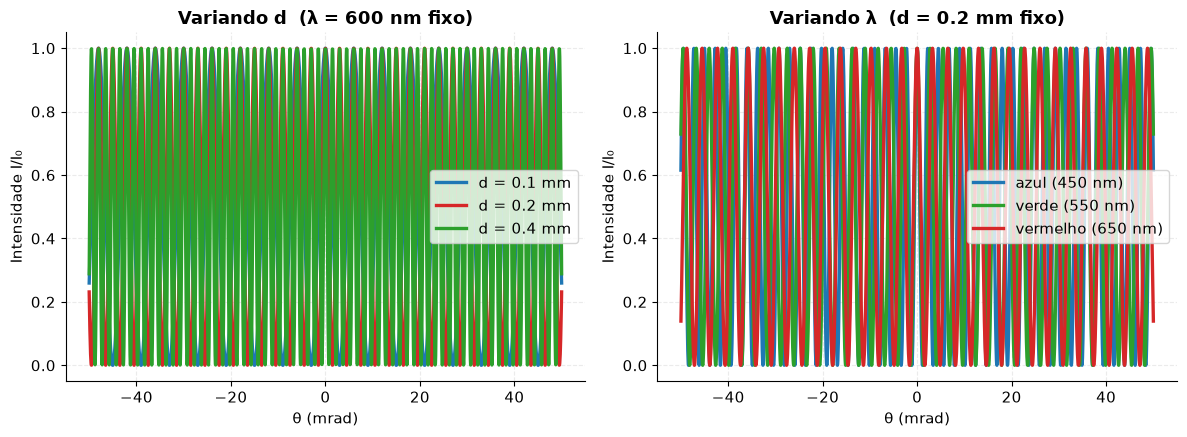

In [2]:
theta = np.linspace(-0.05, 0.05, 2000)  # ângulo pequeno, em radianos

def intensidade_young(theta, d, lam):
    return np.cos(np.pi * d * np.sin(theta) / lam)**2

lam0 = 600e-9  # luz vermelha, 600 nm

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# painel 1: variando d, lambda fixo
for d, cor in zip([0.1e-3, 0.2e-3, 0.4e-3], [AZUL, VERM, VERDE]):
    axes[0].plot(theta*1000, intensidade_young(theta, d, lam0), color=cor,
                 label=f"d = {d*1e3:.1f} mm")
axes[0].set_title(f"Variando d  (λ = {lam0*1e9:.0f} nm fixo)")
axes[0].set_xlabel("θ (mrad)"); axes[0].set_ylabel("Intensidade I/I₀")
axes[0].legend()

# painel 2: variando lambda, d fixo
d0 = 0.2e-3
for lam, cor, nome in zip([450e-9, 550e-9, 650e-9], [AZUL, VERDE, VERM],
                           ["azul (450 nm)", "verde (550 nm)", "vermelho (650 nm)"]):
    axes[1].plot(theta*1000, intensidade_young(theta, d0, lam), color=cor, label=nome)
axes[1].set_title(f"Variando λ  (d = {d0*1e3:.1f} mm fixo)")
axes[1].set_xlabel("θ (mrad)"); axes[1].set_ylabel("Intensidade I/I₀")
axes[1].legend()

plt.tight_layout()
plt.show()


### Frentes de onda circulares de duas fontes coerentes

Outra forma de visualizar a interferência é olhar diretamente para as **frentes de onda** —
círculos concêntricos de crista e vale se espalhando a partir de cada fenda, como ondas circulares
na água. Nos pontos onde duas cristas (ou dois vales) coincidem, a interferência é construtiva;
onde uma crista encontra um vale, é destrutiva. O resultado é o clássico padrão de **"casca de
ovo"**.


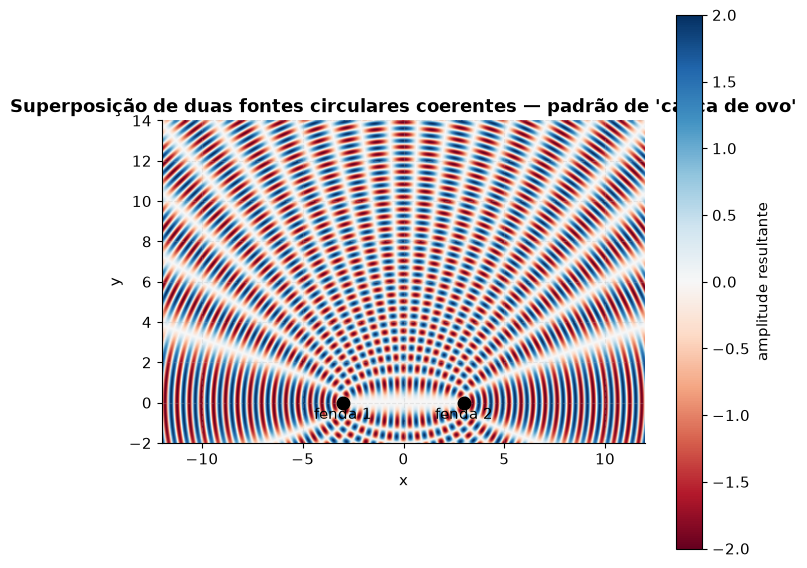

In [3]:
k_wave = 2*np.pi / 0.6   # número de onda (unidades arbitrárias de comprimento)
d_fontes = 6.0            # separação entre as fontes

x = np.linspace(-12, 12, 500)
y = np.linspace(-2, 14, 500)
X, Y = np.meshgrid(x, y)

r1 = np.sqrt((X - d_fontes/2)**2 + Y**2)
r2 = np.sqrt((X + d_fontes/2)**2 + Y**2)

campo = np.sin(k_wave*r1) + np.sin(k_wave*r2)

fig, ax = plt.subplots(figsize=(7, 7))
im = ax.imshow(campo, extent=[x.min(), x.max(), y.min(), y.max()], origin="lower",
               cmap="RdBu", vmin=-2, vmax=2)
ax.plot([-d_fontes/2, d_fontes/2], [0, 0], "o", color="black", markersize=9, zorder=3)
ax.annotate("fenda 1", (-d_fontes/2, -0.8), ha="center")
ax.annotate("fenda 2", (d_fontes/2, -0.8), ha="center")
ax.set_title("Superposição de duas fontes circulares coerentes — padrão de 'casca de ovo'")
ax.set_xlabel("x"); ax.set_ylabel("y")
plt.colorbar(im, ax=ax, label="amplitude resultante", shrink=0.8)
plt.tight_layout()
plt.show()


> **Intuição física:** as linhas radiais de reforço (onde a cor fica sempre bem vermelha ou bem
> azul ao longo de um raio que sai do ponto médio entre as fontes) são justamente as direções de
> interferência construtiva — são elas que, numa tela distante, aparecem como as franjas claras do
> experimento de Young.


<a id="secao2"></a>
## 2. Princípio de Huygens e Difração

### Princípio de Huygens

Christiaan Huygens propôs que **cada ponto de uma frente de onda pode ser pensado como fonte de
pequenas ondaletas secundárias** esféricas (ou circulares, em 2D), que se propagam na mesma
velocidade e frequência da onda original. A nova frente de onda, um instante depois, é a envoltória
(a tangente comum) de todas essas ondaletas. Esse princípio explica de forma geométrica simples por
que as ondas contornam obstáculos e se espalham ao passar por aberturas — o fenômeno da
**difração**.


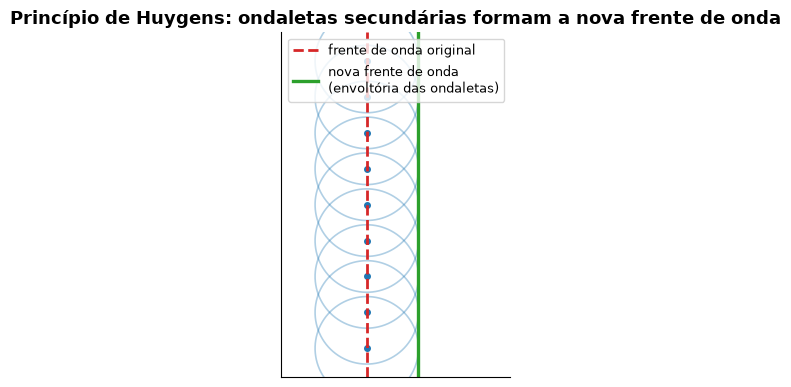

In [4]:
fig, ax = plt.subplots(figsize=(9, 4))

# frente de onda plana incidente (linha vertical) com pontos-fonte
y_pts = np.linspace(-2.5, 2.5, 9)
x0 = 0.0

theta_c = np.linspace(0, 2*np.pi, 100)
raio = 0.9
for yp in y_pts:
    ax.plot(x0 + raio*np.cos(theta_c), yp + raio*np.sin(theta_c), color=AZUL, alpha=0.35, lw=1.2)
    ax.plot(x0, yp, "o", color=AZUL, markersize=4)

# nova frente de onda (envoltória) tangente aos arcos
ax.axvline(x0, color=VERM, lw=2, linestyle="--", label="frente de onda original")
ax.axvline(x0 + raio, color=VERDE, lw=2.4, label="nova frente de onda\n(envoltória das ondaletas)")

ax.set_xlim(-1.5, 2.5); ax.set_ylim(-3, 3)
ax.set_aspect("equal")
ax.set_title("Princípio de Huygens: ondaletas secundárias formam a nova frente de onda")
ax.legend(loc="upper right", fontsize=9)
ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()


### Difração de fenda única

Quando uma onda passa por uma fenda de largura $a$, cada ponto da fenda se torna fonte de
ondaletas de Huygens; a interferência entre essas ondaletas produz um padrão de difração com um
**máximo central largo** e máximos secundários bem mais fracos. A intensidade é dada por

$$I(\theta) = I_0\left(\frac{\sin\beta}{\beta}\right)^2, \qquad
\beta = \frac{\pi a \sin\theta}{\lambda}$$

(a função $\mathrm{sinc}(\beta) = \sin\beta/\beta$). Os mínimos de difração ocorrem em
$a\sin\theta = m\lambda$, $m = \pm1,\pm2,\dots$

> **Intuição física:** quanto mais estreita a fenda (menor $a$, comparado a $\lambda$), mais a
> difração "espalha" a luz — o máximo central fica mais largo. Fendas muito largas ($a \gg
> \lambda$) praticamente não difratam: a luz segue quase em linha reta, como prevê a óptica
> geométrica.


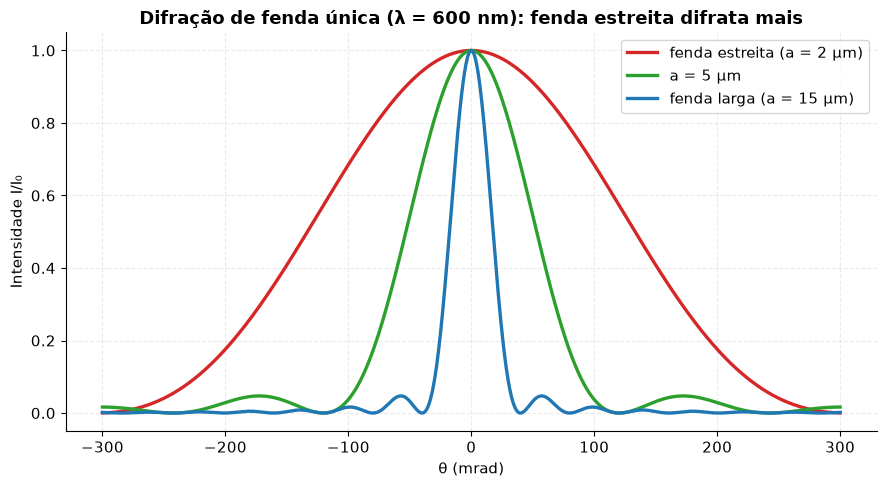

In [5]:
theta = np.linspace(-0.3, 0.3, 3000)
lam = 600e-9

def intensidade_fenda_unica(theta, a, lam):
    beta = np.pi * a * np.sin(theta) / lam
    beta = np.where(np.abs(beta) < 1e-12, 1e-12, beta)
    return (np.sin(beta)/beta)**2

fig, ax = plt.subplots(figsize=(9, 5))
for a, cor, nome in zip([2e-6, 5e-6, 15e-6], [VERM, VERDE, AZUL],
                         ["fenda estreita (a = 2 μm)", "a = 5 μm", "fenda larga (a = 15 μm)"]):
    ax.plot(theta*1000, intensidade_fenda_unica(theta, a, lam), color=cor, label=nome)

ax.set_title(f"Difração de fenda única (λ = {lam*1e9:.0f} nm): fenda estreita difrata mais")
ax.set_xlabel("θ (mrad)"); ax.set_ylabel("Intensidade I/I₀")
ax.legend()
plt.tight_layout()
plt.show()


### Rede de difração: o efeito de aumentar o número de fendas

Uma **rede de difração** tem muitas fendas igualmente espaçadas. A posição dos máximos principais
continua dada por $d\sin\theta = m\lambda$ (igual à dupla fenda), mas à medida que o número de
fendas $N$ aumenta, os máximos ficam **mais estreitos e muito mais intensos** — é esse
estreitamento que torna as redes de difração instrumentos tão precisos para medir comprimentos de
onda (espectroscopia).

$$I(\theta) = I_0 \left(\frac{\sin\beta}{\beta}\right)^2
\left(\frac{\sin(N\gamma)}{\sin\gamma}\right)^2 \Big/ N^2,
\qquad \gamma = \frac{\pi d \sin\theta}{\lambda}$$


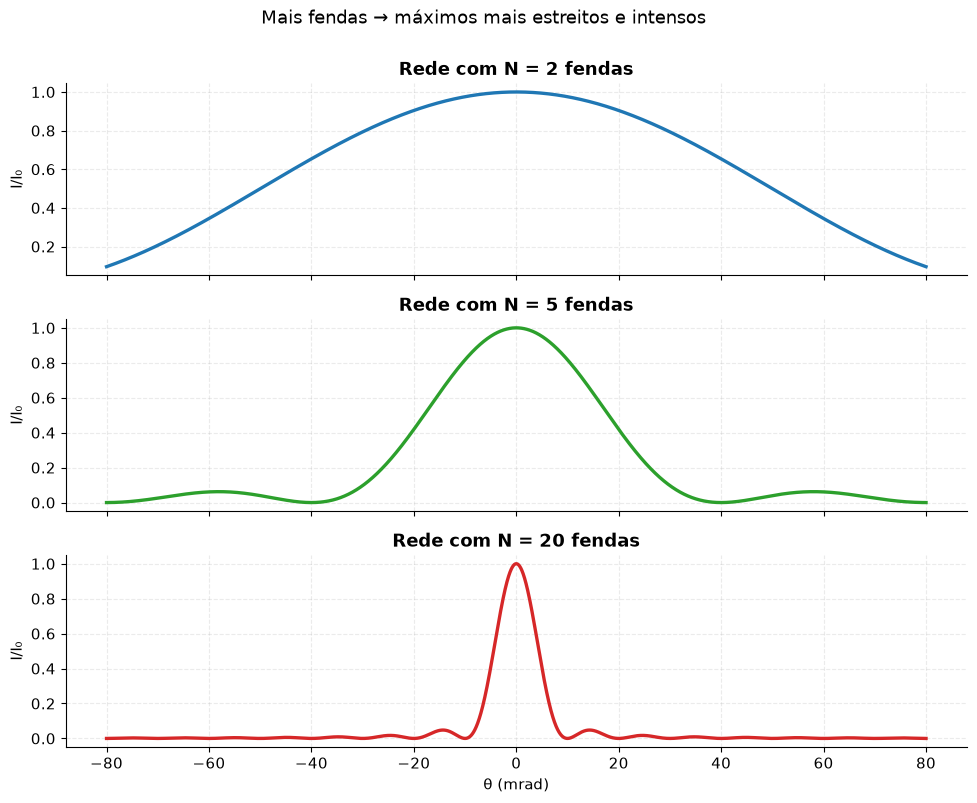

In [6]:
theta = np.linspace(-0.08, 0.08, 4000)
lam = 600e-9
d_rede = 3e-6
a_fenda = 0.3e-6  # fenda bem estreita, para N grande dominar o padrão

def intensidade_rede(theta, N, d, a, lam):
    beta = np.pi * a * np.sin(theta) / lam
    beta = np.where(np.abs(beta) < 1e-12, 1e-12, beta)
    gamma = np.pi * d * np.sin(theta) / lam
    gamma = np.where(np.abs(np.sin(gamma)) < 1e-12, gamma + 1e-9, gamma)
    fator_fenda = (np.sin(beta)/beta)**2
    fator_rede = (np.sin(N*gamma)/(N*np.sin(gamma)))**2
    return fator_fenda * fator_rede

fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
for ax, N, cor in zip(axes, [2, 5, 20], [AZUL, VERDE, VERM]):
    I = intensidade_rede(theta, N, d_rede, a_fenda, lam)
    ax.plot(theta*1000, I, color=cor)
    ax.set_title(f"Rede com N = {N} fendas")
    ax.set_ylabel("I/I₀")
axes[-1].set_xlabel("θ (mrad)")
fig.suptitle("Mais fendas → máximos mais estreitos e intensos", y=1.00)
plt.tight_layout()
plt.show()


<a id="secao3"></a>
## 3. Relatividade

### Postulados da relatividade restrita (Einstein, 1905)

1. **Princípio da relatividade:** as leis da física são as mesmas em todos os referenciais
   inerciais (que se movem com velocidade constante um em relação ao outro).
2. **Constância da velocidade da luz:** a velocidade da luz no vácuo, $c$, tem o mesmo valor em
   todos os referenciais inerciais, independente do movimento da fonte ou do observador.

Desses dois postulados, aparentemente simples, decorrem consequências profundas: o tempo e o
comprimento deixam de ser absolutos e passam a depender do referencial do observador.

### O fator de Lorentz

$$\gamma = \frac{1}{\sqrt{1 - v^2/c^2}}$$

O fator $\gamma \geq 1$ aparece em quase todas as fórmulas relativísticas (dilatação temporal,
contração do comprimento, energia relativística...). Para $v \ll c$, $\gamma \approx 1$ e
recuperamos a física newtoniana; perto de $v=c$, $\gamma \to \infty$.


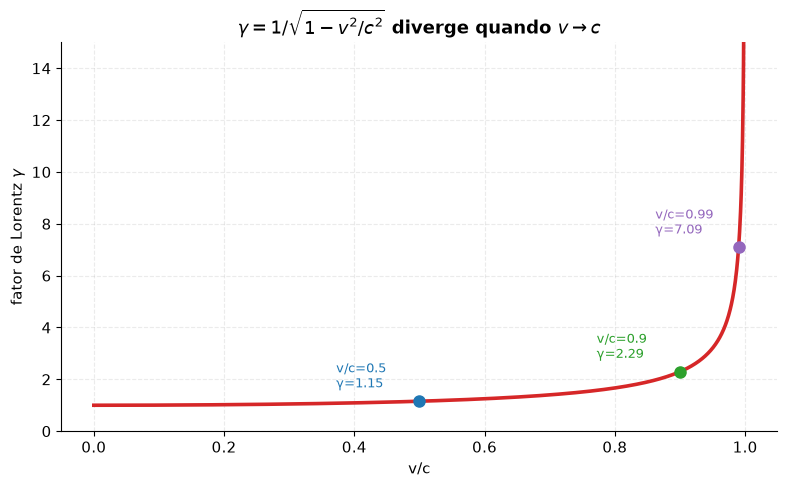

In [7]:
beta = np.linspace(0, 0.999, 2000)  # v/c
gamma = 1/np.sqrt(1 - beta**2)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(beta, gamma, color=VERM, lw=2.6)
for v_frac, cor in zip([0.5, 0.9, 0.99], [AZUL, VERDE, ROXO]):
    g = 1/np.sqrt(1 - v_frac**2)
    ax.plot(v_frac, g, "o", color=cor, markersize=8, zorder=5)
    ax.annotate(f"v/c={v_frac}\nγ={g:.2f}", (v_frac, g), textcoords="offset points",
                xytext=(-60, 10), fontsize=9, color=cor)

ax.set_xlabel("v/c"); ax.set_ylabel(r"fator de Lorentz $\gamma$")
ax.set_title(r"$\gamma = 1/\sqrt{1-v^2/c^2}$ diverge quando $v \to c$")
ax.set_ylim(0, 15)
plt.tight_layout()
plt.show()


### Dilatação temporal: o relógio de luz

Um jeito clássico de visualizar a dilatação temporal é o **relógio de luz**: um pulso de luz
quica entre dois espelhos paralelos, separados por uma distância $L$. No referencial em que o
relógio está parado, o pulso percorre apenas a distância vertical $L$ em cada "tique",
$\Delta t_0 = 2L/c$ (o **tempo próprio**).

Mas, visto de um referencial em que o relógio se move com velocidade $v$, o pulso de luz percorre
um caminho **diagonal** mais longo (o relógio andou para o lado enquanto a luz subia e descia). Como
a velocidade da luz é a mesma em ambos os referenciais, um caminho mais longo percorrido à mesma
velocidade $c$ significa que **mais tempo se passa** nesse referencial:

$$\Delta t = \gamma \, \Delta t_0$$


In [8]:
L = 1.0       # distância entre espelhos (unidades arbitrárias)
v_beta = 0.6  # v/c do relógio no referencial "em movimento"
gamma_rel = 1/np.sqrt(1 - v_beta**2)

n_frames = 60
t = np.linspace(0, 2, n_frames)  # tempo normalizado (0 a 2 = ida e volta, no ref. próprio)

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(11, 5))

for ax, titulo in zip([ax0, ax1], ["Referencial PRÓPRIO (relógio parado)",
                                     "Referencial do observador (relógio em movimento)"]):
    ax.set_xlim(-0.8, 2.8); ax.set_ylim(-0.2, 1.2)
    ax.set_title(titulo, fontsize=11)
    ax.set_xticks([]); ax.set_yticks([])

# espelhos no referencial próprio: parados, em x=0
ax0.axhline(0, color="gray", lw=3); ax0.axhline(L, color="gray", lw=3)
pulso0, = ax0.plot([], [], "o-", color=LARANJ, markersize=10, lw=2)

# espelhos no referencial do observador: a "caixa" se move para a direita
ax1.axhline(0, color="gray", lw=0)  # placeholder
pulso1, = ax1.plot([], [], "o-", color=LARANJ, markersize=10, lw=2)
espelho_inf, = ax1.plot([], [], color="gray", lw=3)
espelho_sup, = ax1.plot([], [], color="gray", lw=3)
texto_t0 = ax0.text(0.02, 0.95, "", transform=ax0.transAxes, fontsize=10)
texto_t1 = ax1.text(0.02, 0.95, "", transform=ax1.transAxes, fontsize=10)

def zigzag_y(tt):
    # posição vertical do pulso: sobe (0->1) e desce (1->2), período 2
    tt_mod = tt % 2
    return tt_mod if tt_mod <= 1 else 2 - tt_mod

def init():
    pulso0.set_data([], []); pulso1.set_data([], [])
    espelho_inf.set_data([], []); espelho_sup.set_data([], [])
    return pulso0, pulso1, espelho_inf, espelho_sup

def animar(i):
    tt = t[i]
    y0 = zigzag_y(tt) * L
    pulso0.set_data([0], [y0])
    texto_t0.set_text(f"t_próprio = {tt:.2f} (unid. de L/c)")

    # no referencial do observador, o relógio avançou v*t_obs; mas o tempo "roda" mais devagar
    # para o pulso completar o mesmo ciclo vertical ele demora gamma vezes mais em t_obs
    tt_obs = tt  # usamos o mesmo parâmetro de desenho, só mudando a trajetória (diagonal)
    y1 = zigzag_y(tt) * L
    x_centro = 0.9 * tt_obs
    x1 = x_centro
    pulso1.set_data([x1], [y1])
    espelho_inf.set_data([x_centro - 0.5, x_centro + 0.5], [0, 0])
    espelho_sup.set_data([x_centro - 0.5, x_centro + 0.5], [L, L])
    texto_t1.set_text(f"t_observador ≈ γ·t_próprio = {gamma_rel*tt:.2f}\n(caminho diagonal, mais longo)")
    return pulso0, pulso1, espelho_inf, espelho_sup

anim = animation.FuncAnimation(fig, animar, init_func=init, frames=n_frames,
                                interval=80, blit=True)
plt.tight_layout()
plt.close(fig)
HTML(anim.to_jshtml())


> **Intuição física:** no referencial do observador, o pulso de luz percorre um caminho
> diagonal (hipotenusa), estritamente mais longo que o caminho vertical (cateto) visto no
> referencial próprio. Como a velocidade da luz $c$ é a mesma para os dois, percorrer uma
> distância maior à mesma velocidade exige mais tempo — daí $\Delta t = \gamma\,\Delta t_0 \geq
> \Delta t_0$. A **contração do comprimento**, $L = L_0/\gamma$, é o efeito espelhado: comprimentos
> medidos na direção do movimento encolhem no referencial em que o objeto se move.


### Diagrama de espaço-tempo (Minkowski)

Um diagrama de espaço-tempo representa a posição $x$ no eixo horizontal e $ct$ (tempo multiplicado
por $c$, para ter unidades de comprimento) no eixo vertical. A trajetória de um objeto nesse
diagrama é chamada **linha de mundo**. Como nenhuma partícula com massa pode atingir ou superar
$c$, toda linha de mundo deve ficar dentro do **cone de luz** — a região limitada pelas retas
$x = \pm ct$, que representam o próprio feixe de luz partindo da origem.


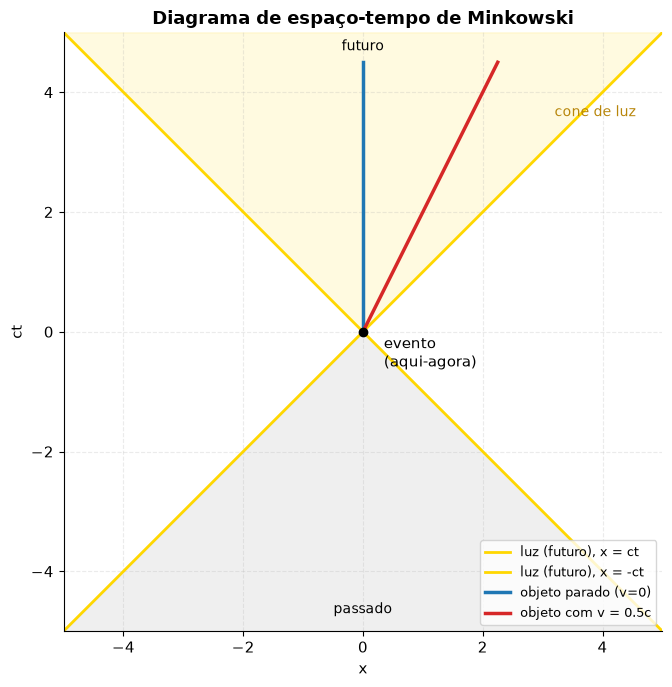

In [9]:
fig, ax = plt.subplots(figsize=(7, 7))

ct = np.linspace(-5, 5, 100)
ax.plot(ct, ct, color="gold", lw=2, label="luz (futuro), x = ct")
ax.plot(-ct, ct, color="gold", lw=2, label="luz (futuro), x = -ct")
ax.fill_between(ct, np.abs(ct), 5, color="gold", alpha=0.12)
ax.fill_between(ct, -np.abs(ct), -5, color="gray", alpha=0.12)

# linha de mundo de um objeto parado (vertical)
ax.plot([0, 0], [0, 4.5], color=AZUL, lw=2.5, label="objeto parado (v=0)")
# linha de mundo de um objeto com v = 0.5c
t_mov = np.linspace(0, 4.5, 50)
ax.plot(0.5*t_mov, t_mov, color=VERM, lw=2.5, label="objeto com v = 0.5c")
# evento na origem
ax.plot(0, 0, "ko", markersize=6, zorder=5)
ax.annotate("evento\n(aqui-agora)", (0, 0), textcoords="offset points", xytext=(15, -25))

ax.annotate("futuro", (0, 4.7), ha="center", fontsize=10)
ax.annotate("passado", (0, -4.7), ha="center", fontsize=10)
ax.annotate("cone de luz", (3.2, 3.6), color="#b8860b", fontsize=10)

ax.set_xlim(-5, 5); ax.set_ylim(-5, 5)
ax.set_xlabel("x"); ax.set_ylabel("ct")
ax.set_title("Diagrama de espaço-tempo de Minkowski")
ax.legend(loc="lower right", fontsize=9)
ax.set_aspect("equal")
plt.tight_layout()
plt.show()


> **Intuição física:** como toda linha de mundo de uma partícula material tem inclinação mais
> "vertical" que $45°$ (ou seja, $|dx/d(ct)| < 1 \Leftrightarrow v < c$), ela nunca consegue
> escapar do cone de luz — é exatamente essa restrição geométrica que impede viagens mais rápidas
> que a luz.


<a id="secao4"></a>
## 4. Fótons, Elétrons e Átomos

### Efeito fotoelétrico

Quando luz incide sobre uma superfície metálica, elétrons podem ser ejetados — mas só se a
**frequência** da luz for alta o suficiente, não importa quão intensa seja a luz (um fato que a
física clássica não conseguia explicar). Einstein propôs que a luz é composta de **fótons**, cada
um carregando energia $E = hf$. Um elétron absorve um fóton inteiro; se $hf$ for maior que a função
trabalho $\phi$ do metal (energia mínima para arrancar o elétron), o excesso vira energia cinética:

$$K_{\max} = hf - \phi$$

Abaixo da frequência de corte $f_0 = \phi/h$, nenhum elétron é ejetado, não importa a intensidade.


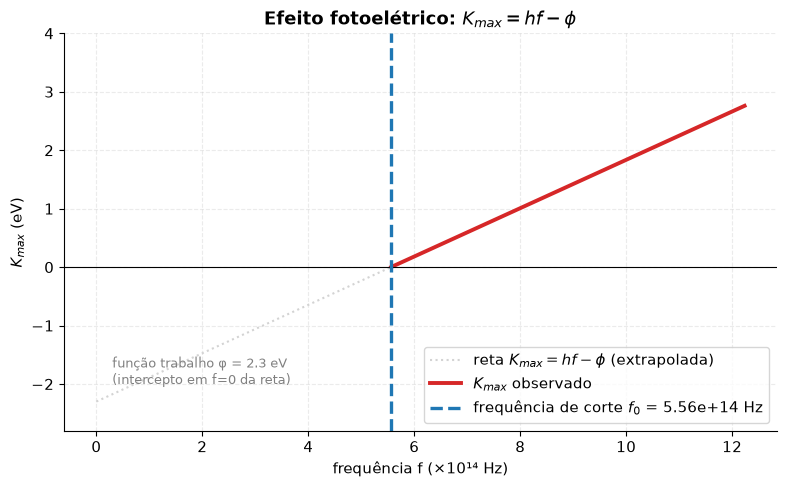

In [10]:
phi_eV = 2.3  # função trabalho típica (ex.: sódio), em eV
f0 = phi_eV / h_eV  # frequência de corte (Hz)

f = np.linspace(0, 2.2*f0, 500)
Kmax = np.where(f > f0, h_eV*f - phi_eV, np.nan)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(f/1e14, h_eV*f - phi_eV, color="lightgray", lw=1.5, linestyle=":",
        label="reta $K_{max}=hf-\\phi$ (extrapolada)")
ax.plot(f/1e14, Kmax, color=VERM, lw=2.8, label="$K_{max}$ observado")
ax.axhline(0, color="black", lw=0.8)
ax.axvline(f0/1e14, color=AZUL, linestyle="--", label=f"frequência de corte $f_0$ = {f0:.2e} Hz")
ax.annotate(f"função trabalho φ = {phi_eV} eV\n(intercepto em f=0 da reta)", (0.3, -phi_eV+0.3),
            fontsize=9, color="gray")
ax.set_xlabel("frequência f (×10¹⁴ Hz)"); ax.set_ylabel("$K_{max}$ (eV)")
ax.set_title("Efeito fotoelétrico: $K_{max} = hf - \\phi$")
ax.legend()
ax.set_ylim(-phi_eV-0.5, 4)
plt.tight_layout()
plt.show()


> **Intuição física:** a inclinação da reta é a constante de Planck $h$ (em eV·s, se o eixo
> horizontal for frequência) — é assim, medindo essa inclinação experimentalmente (Millikan,
> 1916), que $h$ foi confirmada. O intercepto negativo no eixo vertical é $-\phi$: quanto maior a
> função trabalho, maior a frequência de corte necessária.


### O átomo de hidrogênio de Bohr

No modelo de Bohr, os elétrons do átomo de hidrogênio só podem ocupar órbitas com energias
quantizadas:

$$E_n = -\frac{13.6\ \text{eV}}{n^2}, \qquad n = 1, 2, 3, \dots$$

Quando um elétron cai de um nível $n_i$ para um nível $n_f < n_i$, o átomo emite um fóton com
energia $E_{\text{fóton}} = E_{n_i} - E_{n_f}$. As transições que terminam em $n_f=1$ formam a
**série de Lyman** (ultravioleta), em $n_f=2$ a **série de Balmer** (visível) e em $n_f=3$ a
**série de Paschen** (infravermelho).


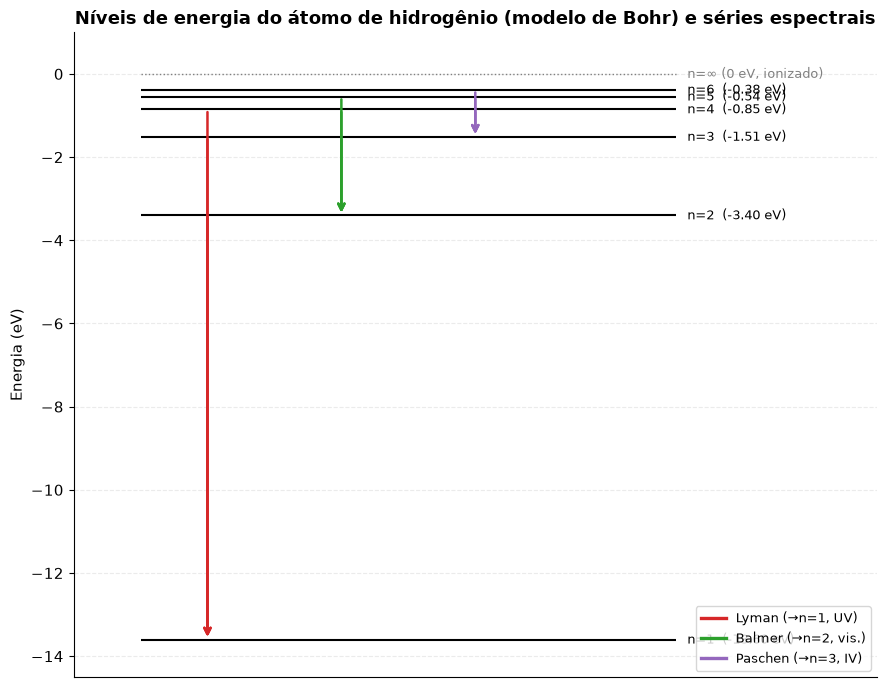

In [11]:
def E_bohr(n):
    return -13.6 / n**2

n_max = 6
niveis = np.arange(1, n_max+1)

fig, ax = plt.subplots(figsize=(9, 7))
for n in niveis:
    ax.hlines(E_bohr(n), 0.3, 2.7, color="black", lw=1.5)
    ax.text(2.75, E_bohr(n), f"n={n}  ({E_bohr(n):.2f} eV)", va="center", fontsize=9)
ax.hlines(0, 0.3, 2.7, color="gray", lw=1, linestyle=":")
ax.text(2.75, 0, "n=∞ (0 eV, ionizado)", va="center", fontsize=9, color="gray")

series = {
    "Lyman (→n=1, UV)":   (VERM,   [(2,1), (3,1), (4,1)]),
    "Balmer (→n=2, vis.)": (VERDE, [(3,2), (4,2), (5,2)]),
    "Paschen (→n=3, IV)":  (ROXO,  [(4,3), (5,3), (6,3)]),
}

x_series = {"Lyman (→n=1, UV)": 0.6, "Balmer (→n=2, vis.)": 1.2, "Paschen (→n=3, IV)": 1.8}
for nome, (cor, transicoes) in series.items():
    x0 = x_series[nome]
    for (ni, nf) in transicoes:
        ax.annotate("", xy=(x0, E_bohr(nf)), xytext=(x0, E_bohr(ni)),
                    arrowprops=dict(arrowstyle="->", color=cor, lw=1.8))
    ax.plot([], [], color=cor, label=nome)  # para a legenda

ax.set_xlim(0, 3.6)
ax.set_ylim(-14.5, 1)
ax.set_xticks([])
ax.set_ylabel("Energia (eV)")
ax.set_title("Níveis de energia do átomo de hidrogênio (modelo de Bohr) e séries espectrais")
ax.legend(loc="lower right", fontsize=9)
plt.tight_layout()
plt.show()


> **Intuição física:** as setas mais longas (maior salto de energia) correspondem a fótons
> mais energéticos — e, portanto, de maior frequência / menor comprimento de onda. É por isso que
> a série de Lyman (que termina no estado fundamental, $n=1$) é ultravioleta, enquanto Paschen
> (termina em $n=3$, saltos menores) é infravermelha.


<a id="secao5"></a>
## 5. A natureza ondulatória das partículas

### Comprimento de onda de de Broglie

Louis de Broglie propôs, em 1924, que toda partícula com momento $p = mv$ tem associado a si um
comprimento de onda

$$\lambda = \frac{h}{p} = \frac{h}{mv}$$

Para objetos macroscópicos, $\lambda$ é absurdamente pequeno — por isso nunca observamos efeitos
ondulatórios no dia a dia. Só para partículas muito leves (elétrons, nêutrons) e/ou muito lentas o
comprimento de onda se torna comparável a distâncias atômicas, e os efeitos ondulatórios (como
difração) tornam-se observáveis.


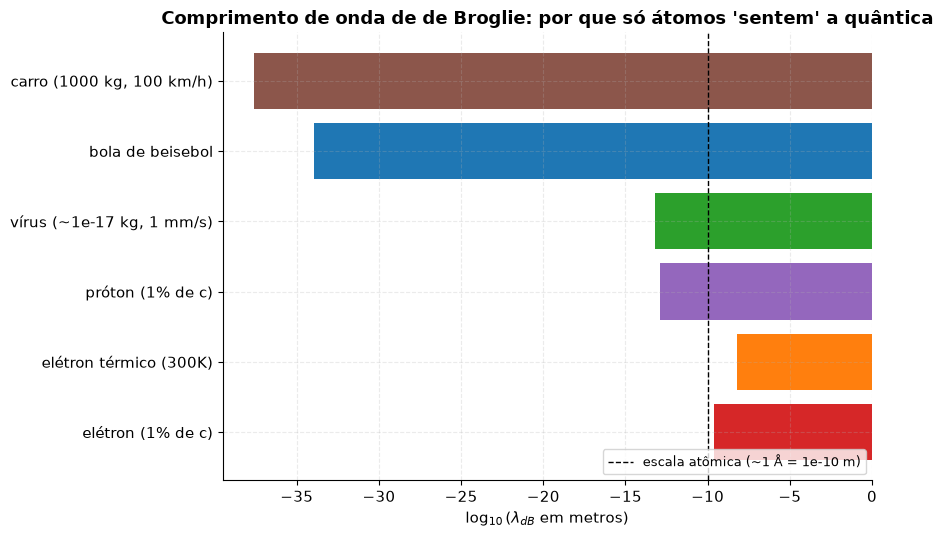

elétron (1% de c)                 λ_dB = 2.426e-10 m
elétron térmico (300K)            λ_dB = 6.217e-09 m
próton (1% de c)                  λ_dB = 1.321e-13 m
vírus (~1e-17 kg, 1 mm/s)         λ_dB = 6.626e-14 m
bola de beisebol                  λ_dB = 1.142e-34 m
carro (1000 kg, 100 km/h)         λ_dB = 2.383e-38 m


In [12]:
def lambda_de_broglie(m, v):
    return h_planck / (m * v)

objetos = [
    ("elétron (1% de c)",        m_eletron,          0.01*c_luz,  VERM),
    ("elétron térmico (300K)",   m_eletron,          1.17e5,      LARANJ),
    ("próton (1% de c)",         1.673e-27,          0.01*c_luz,  ROXO),
    ("vírus (~1e-17 kg, 1 mm/s)",1e-17,              1e-3,        VERDE),
    ("bola de beisebol",         0.145,              40.0,        AZUL),
    ("carro (1000 kg, 100 km/h)",1000.0,             27.8,        MARROM),
]

fig, ax = plt.subplots(figsize=(9, 5.5))
nomes = [o[0] for o in objetos]
lambdas = [lambda_de_broglie(o[1], o[2]) for o in objetos]
cores = [o[3] for o in objetos]

y_pos = np.arange(len(objetos))
ax.barh(y_pos, np.log10(lambdas), color=cores)
ax.set_yticks(y_pos); ax.set_yticklabels(nomes)
ax.set_xlabel(r"$\log_{10}(\lambda_{dB}$ em metros$)$")
ax.axvline(np.log10(1e-10), color="black", linestyle="--", lw=1,
           label="escala atômica (~1 Å = 1e-10 m)")
ax.set_title("Comprimento de onda de de Broglie: por que só átomos 'sentem' a quântica")
ax.legend(loc="lower right", fontsize=9)
plt.tight_layout()
plt.show()

for nome, lam in zip(nomes, lambdas):
    print(f"{nome:32s}  λ_dB = {lam:.3e} m")


> **Intuição física:** o comprimento de onda de de Broglie de uma bola de beisebol é cerca de
> **20 ordens de grandeza** menor que o tamanho de um núcleo atômico — não há como observar
> difração ou interferência numa bola. Já um elétron de baixa energia tem $\lambda$ da ordem do
> espaçamento atômico em um cristal, o que torna possível difratar elétrons numa rede cristalina
> (experimento de Davisson–Germer) exatamente como se difrata luz numa rede óptica.

### Dupla fenda com elétrons

O experimento de dupla fenda da Seção 1, originalmente feito com luz, também funciona com
**elétrons** disparados um de cada vez! Mesmo passando "de um em um", depois de muitos elétrons o
padrão acumulado na tela é um padrão de interferência idêntico ao da luz — a mesma
$I(\theta)=I_0\cos^2(\pi d\sin\theta/\lambda_{dB})$ da Seção 1, agora com $\lambda_{dB}=h/p$ no
lugar do comprimento de onda da luz. Isso mostra que **cada elétron individual "interfere consigo
mesmo"**, comportando-se como uma onda de probabilidade que passa pelas duas fendas simultaneamente.


<a id="secao6"></a>
## 6. Mecânica quântica

### Princípio da incerteza de Heisenberg

$$\Delta x \, \Delta p \geq \frac{\hbar}{2}$$

Não é uma limitação de instrumentos de medida — é uma propriedade fundamental de qualquer onda:
um pacote de onda muito **localizado no espaço** (pequeno $\Delta x$) necessariamente contém uma
**ampla gama de números de onda / momentos** (grande $\Delta p$), e vice-versa. Isso é uma
consequência direta das propriedades da transformada de Fourier, aplicada à função de onda
$\psi(x)$.


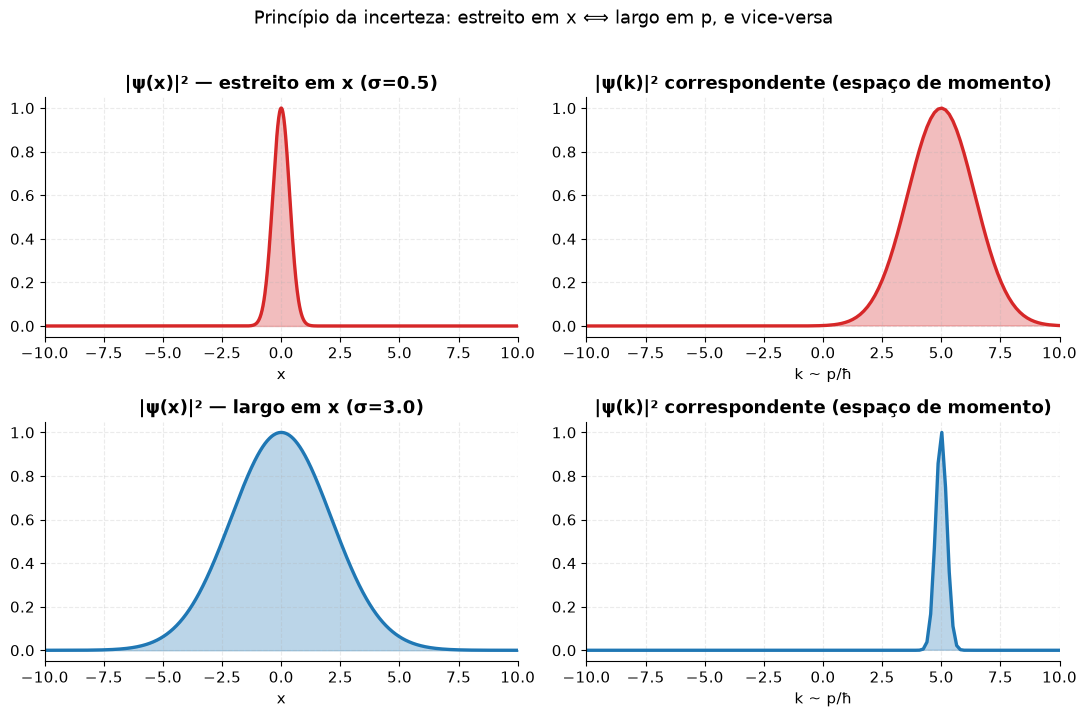

In [13]:
def pacote_gaussiano(x, x0, sigma):
    return np.exp(-(x-x0)**2/(2*sigma**2)) * np.exp(1j*5*x)  # com uma portadora para variar

x = np.linspace(-20, 20, 2048)
dx = x[1]-x[0]

fig, axes = plt.subplots(2, 2, figsize=(11, 7))

for sigma, cor, rotulo in zip([0.5, 3.0], [VERM, AZUL], ["estreito em x (σ=0.5)", "largo em x (σ=3.0)"]):
    psi = pacote_gaussiano(x, 0, sigma)
    dens_x = np.abs(psi)**2

    psi_k = np.fft.fftshift(np.fft.fft(psi))
    k = np.fft.fftshift(np.fft.fftfreq(len(x), d=dx)) * 2*np.pi
    dens_k = np.abs(psi_k)**2
    dens_k /= dens_k.max()

    row = 0 if sigma < 1 else 1
    axes[row, 0].plot(x, dens_x, color=cor)
    axes[row, 0].fill_between(x, dens_x, color=cor, alpha=0.3)
    axes[row, 0].set_title(f"|ψ(x)|² — {rotulo}")
    axes[row, 0].set_xlabel("x"); axes[row, 0].set_xlim(-10, 10)

    axes[row, 1].plot(k, dens_k, color=cor)
    axes[row, 1].fill_between(k, dens_k, color=cor, alpha=0.3)
    axes[row, 1].set_title(f"|ψ(k)|² correspondente (espaço de momento)")
    axes[row, 1].set_xlabel("k ~ p/ħ"); axes[row, 1].set_xlim(-10, 10)

fig.suptitle("Princípio da incerteza: estreito em x ⟺ largo em p, e vice-versa", y=1.02)
plt.tight_layout()
plt.show()


> **Intuição física:** repare que o pacote estreito no espaço real (linha vermelha, acima) é o
> que fica **largo** no espaço de momento, e o pacote largo no espaço real (linha azul, abaixo)
> fica **estreito** em momento. Não há como ter os dois estreitos ao mesmo tempo — essa é a
> essência matemática do princípio da incerteza.

### Partícula numa caixa (poço de potencial infinito)

Para uma partícula confinada numa caixa unidimensional de largura $L$ (paredes de potencial
infinito), a equação de Schrödinger só admite soluções estacionárias com energias quantizadas:

$$\psi_n(x) = \sqrt{\frac{2}{L}}\sin\left(\frac{n\pi x}{L}\right), \qquad
E_n = \frac{n^2\pi^2\hbar^2}{2mL^2} \propto n^2, \qquad n=1,2,3,\dots$$


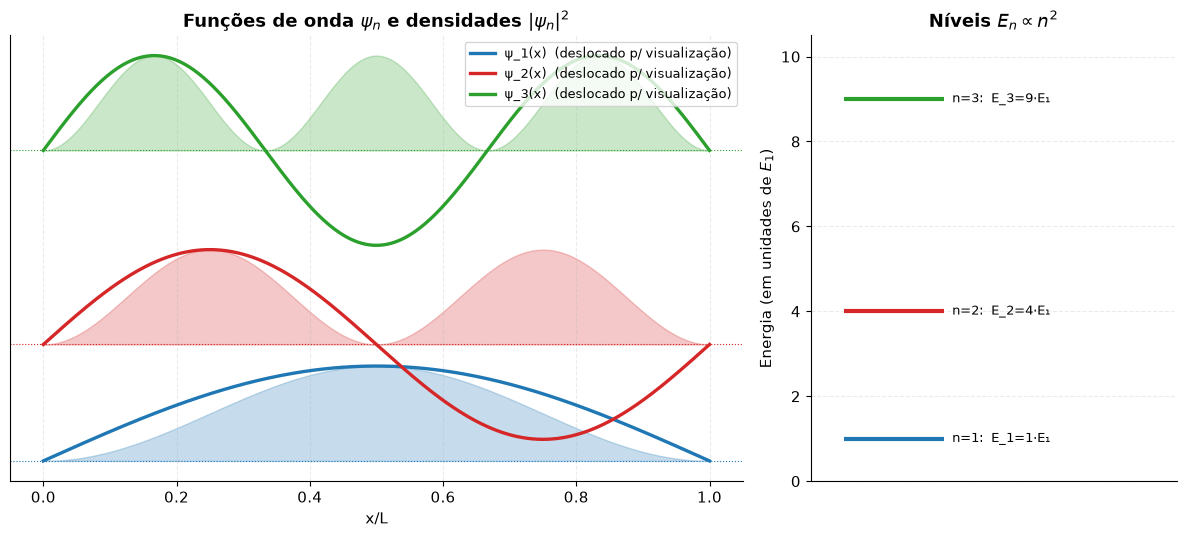

In [14]:
L = 1.0  # largura da caixa (unidades arbitrárias)
x = np.linspace(0, L, 400)

def psi_n(n, x, L=L):
    return np.sqrt(2/L) * np.sin(n*np.pi*x/L)

def E_n(n, L=L):
    return n**2  # proporcional; unidades arbitrárias (E1 = 1)

fig, (ax_wave, ax_levels) = plt.subplots(1, 2, figsize=(12, 5.5),
                                          gridspec_kw={"width_ratios": [2, 1]})

cores_n = [AZUL, VERM, VERDE]
offset_escala = 2.2
for n, cor in zip([1, 2, 3], cores_n):
    offset = E_n(n) * 0.9
    psi = psi_n(n, x)
    dens = psi**2
    ax_wave.plot(x, offset + offset_escala*psi/np.max(np.abs(psi)), color=cor,
                 label=f"ψ_{n}(x)  (deslocado p/ visualização)")
    ax_wave.fill_between(x, offset, offset + offset_escala*dens/np.max(dens), color=cor, alpha=0.25)
    ax_wave.axhline(offset, color=cor, lw=0.8, linestyle=":")

ax_wave.set_xlabel("x/L"); ax_wave.set_title(r"Funções de onda $\psi_n$ e densidades $|\psi_n|^2$")
ax_wave.legend(fontsize=9, loc="upper right")
ax_wave.set_yticks([])

for n, cor in zip([1, 2, 3], cores_n):
    ax_levels.hlines(E_n(n), 0.2, 0.8, color=cor, lw=3)
    ax_levels.text(0.85, E_n(n), f"n={n}:  E_{n}={E_n(n)}·E₁", va="center", fontsize=9)
ax_levels.set_xlim(0, 2.2); ax_levels.set_ylim(0, 10.5)
ax_levels.set_xticks([]); ax_levels.set_ylabel(r"Energia (em unidades de $E_1$)")
ax_levels.set_title(r"Níveis $E_n \propto n^2$")

plt.tight_layout()
plt.show()


> **Intuição física:** cada função de onda deve valer exatamente zero nas paredes da caixa
> (condição de contorno), o que só é possível para um número inteiro de "meias ondas" dentro da
> caixa. É essa condição puramente geométrica/ondulatória que gera a quantização discreta da
> energia — nenhum postulado extra é necessário além de tratar $\psi$ como uma onda.


<a id="secao7"></a>
## 7. Estrutura atômica

### Números quânticos e orbitais

O estado de um elétron num átomo de hidrogênio é descrito por três números quânticos (mais o spin):

| Número quântico | Símbolo | Valores possíveis | O que descreve |
|---|---|---|---|
| Principal | $n$ | $1, 2, 3,\dots$ | energia / tamanho do orbital |
| Azimutal (momento angular) | $l$ | $0, 1, \dots, n-1$ | forma do orbital (s, p, d, f...) |
| Magnético | $m_l$ | $-l,\dots,0,\dots,+l$ | orientação espacial do orbital |

Orbitais $l=0$ são chamados **s** (esfericamente simétricos), $l=1$ são **p** (com dois lóbulos),
$l=2$ são **d**, etc.


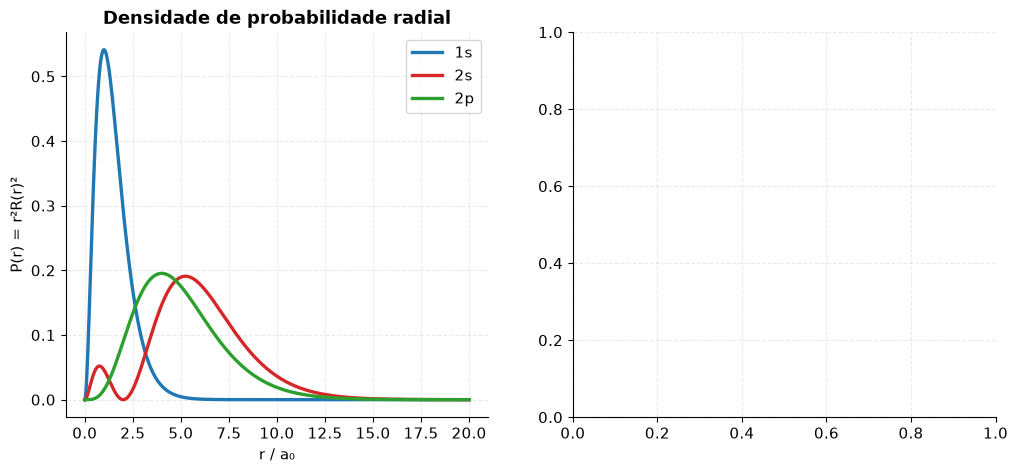

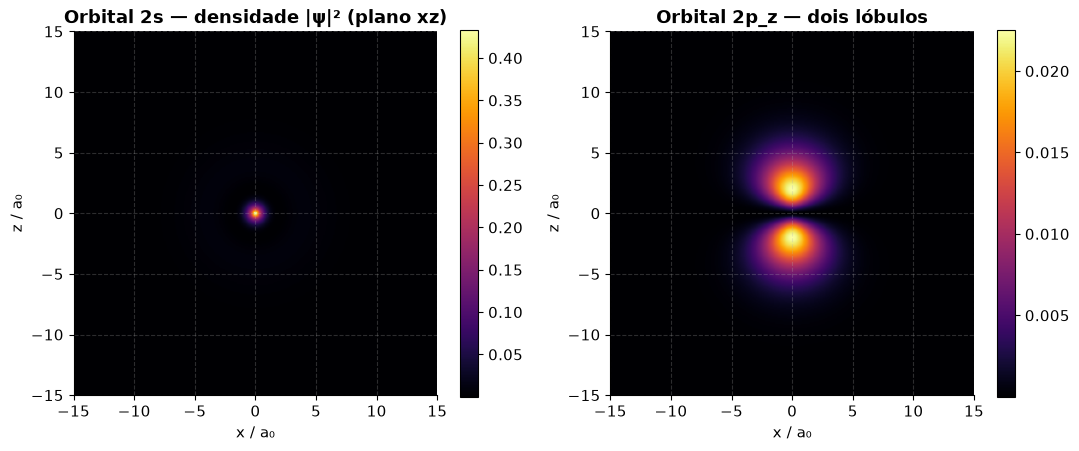

In [15]:
# Funções de onda radiais do hidrogênio (em unidades do raio de Bohr a0=1), fórmulas explícitas
a0 = 1.0

def R_1s(r):
    return 2 * a0**(-1.5) * np.exp(-r/a0)

def R_2s(r):
    return (1/(2*np.sqrt(2))) * a0**(-1.5) * (2 - r/a0) * np.exp(-r/(2*a0))

def R_2p(r):
    return (1/(2*np.sqrt(6))) * a0**(-1.5) * (r/a0) * np.exp(-r/(2*a0))

r = np.linspace(0, 20, 600)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# densidade de probabilidade radial: P(r) = r^2 * R(r)^2  (prob. de achar o elétron entre r e r+dr)
for R, nome, cor in zip([R_1s, R_2s, R_2p], ["1s", "2s", "2p"], [AZUL, VERM, VERDE]):
    P = r**2 * R(r)**2
    axes[0].plot(r, P, color=cor, label=nome)
axes[0].set_xlabel("r / a₀"); axes[0].set_ylabel("P(r) = r²R(r)²")
axes[0].set_title("Densidade de probabilidade radial")
axes[0].legend()

# mapa 2D de densidade de probabilidade no plano xz: s (esférico) vs p (dois lóbulos)
N = 300
lim = 15
xx = np.linspace(-lim, lim, N)
zz = np.linspace(-lim, lim, N)
XX, ZZ = np.meshgrid(xx, zz)
RR = np.sqrt(XX**2 + ZZ**2)
theta_ang = np.arctan2(XX, ZZ)  # ângulo em relação ao eixo z

dens_2s = R_2s(RR)**2                       # s: sem dependência angular
dens_2pz = (R_2p(RR)**2) * np.cos(theta_ang)**2  # p_z: fator angular cos^2(theta)

fig2, axes2 = plt.subplots(1, 2, figsize=(11, 5))
im0 = axes2[0].imshow(dens_2s, extent=[-lim, lim, -lim, lim], cmap="inferno", origin="lower")
axes2[0].set_title("Orbital 2s — densidade |ψ|² (plano xz)")
im1 = axes2[1].imshow(dens_2pz, extent=[-lim, lim, -lim, lim], cmap="inferno", origin="lower")
axes2[1].set_title("Orbital 2p_z — dois lóbulos")
for ax_ in axes2:
    ax_.set_xlabel("x / a₀"); ax_.set_ylabel("z / a₀")
plt.colorbar(im0, ax=axes2[0], shrink=0.8)
plt.colorbar(im1, ax=axes2[1], shrink=0.8)

plt.tight_layout()
plt.show()


> **Intuição física:** o orbital **s** (esquerda) é esfericamente simétrico — não importa a
> direção, só a distância ao núcleo. Já o orbital **p** tem um **nó** exatamente no núcleo (o
> fator angular $\cos^2\theta$ se anula no plano equatorial) e dois lóbulos opostos ao longo do
> eixo — essa estrutura direcional dos orbitais p (e d, f...) é o que explica a geometria das
> ligações químicas e a forma das moléculas.


## Conclusão

Partimos da interferência e difração de ondas de luz, passamos pela relatividade restrita — onde
espaço e tempo deixam de ser absolutos — e terminamos na física quântica, onde a própria distinção
entre "onda" e "partícula" se dissolve. Esses três blocos, aparentemente distintos, compartilham
uma mesma linguagem matemática: a de ondas e suas superposições. É essa linguagem comum que torna
a luz, a matéria e o próprio espaço-tempo descritíveis dentro de um único arcabouço teórico.
